In [1]:
#### PRELIMINARY CARBON DEPOSITION DATASET ANALYSIS ####
import pandas as pd
import numpy as np

### Loading the dataset ###
CSV_PATH = "/content/CARBON___DEPOSITION___DATA.csv"
raw_df = pd.read_csv(CSV_PATH)
raw_df.columns = [c.strip() for c in raw_df.columns]


feature_cols = ["T_C","Fo_CH4_m3_per_h","X_CH4_conv_pct","P_input_W","TOS_h"]
target_cols  = ["M_C_kg", "CFR_kg_per_h"]

## Data Cleaning ---> Coerce to numeric & drop NaNs on required columns ##
for c in feature_cols + target_cols:
    raw_df[c] = pd.to_numeric(raw_df[c], errors="coerce")

df_clean = raw_df.dropna(subset=feature_cols + target_cols).copy()

df_clean["M_C_g"]       = 1000.0 * df_clean["M_C_kg"]
df_clean["CFR_g_per_h"] = 1000.0 * df_clean["CFR_kg_per_h"]

## Optional: Enforce non-negativity if physical (Optional) #
df_clean["M_C_g"]       = np.maximum(df_clean["M_C_g"], 0.0)
df_clean["CFR_g_per_h"] = np.maximum(df_clean["CFR_g_per_h"], 0.0)
print("RAW rows:", len(raw_df), " | Clean rows:", len(df_clean))


## Descriptive Statistics ##
desc_cols = feature_cols + ["M_C_g","CFR_g_per_h"]
print("\n### 1) Descriptive Statistics (RAW cleaned) ###\n")
print(df_clean[desc_cols].describe().to_string())

## Correlation Analysis ##
corr_cols = [
    "T_C","Fo_CH4_m3_per_h","X_CH4_conv_pct","P_input_W","TOS_h",
    "M_C_g","CFR_g_per_h"
]
corr_mat = df_clean[corr_cols].corr(numeric_only=True)

print("\n### 2) Correlation Matrix (RAW cleaned) ###\n")
print(corr_mat.to_string())


## Binned analysis with respect to the power input ##
bins = [0, 500, 1000, 1500, 2500, 4000, 6000]
labels = ["0-500","501-1000","1001-1500","1501-2500","2501-4000","4001-6000"]
df_clean["P_bin"] = pd.cut(df_clean["P_input_W"], bins=bins, labels=labels, include_lowest=True)
binned = df_clean.groupby("P_bin")[["M_C_g","CFR_g_per_h"]].agg(
    mean_M=("M_C_g","mean"),
    median_M=("M_C_g","median"),
    mean_CFR=("CFR_g_per_h","mean"),
    median_CFR=("CFR_g_per_h","median"),
    count=("M_C_g","count")
)

print("\n### 3) Binned Analysis by P_input_W (RAW cleaned) ###\n")
print(binned.to_string())

### IDENTIFY THE BEST OPERATING POINT ###

## (A) Maximize carbon mass deposited ##
idx_max_M = df_clean["M_C_g"].idxmax()
row_max_M = df_clean.loc[idx_max_M, feature_cols + ["M_C_g","CFR_g_per_h"]]
print("\n### 4A) Operating point with MAX M_C_g ###\n")
print(row_max_M.to_string())

# (B) Maximize deposition efficiency proxy (M_C_g per unit power)
df_clean["M_per_W"] = df_clean["M_C_g"] / (df_clean["P_input_W"] + 1e-12)
idx_best_eff = df_clean["M_per_W"].idxmax()
row_best_eff = df_clean.loc[idx_best_eff, feature_cols + ["M_C_g","CFR_g_per_h","M_per_W"]]

print("\n### 4B) Operating point with MAX (M_C_g / P_input_W) ###\n")
print(row_best_eff.to_string())

RAW rows: 100  | Clean rows: 100

### 1) Descriptive Statistics (RAW cleaned) ###

              T_C  Fo_CH4_m3_per_h  X_CH4_conv_pct  P_input_W       TOS_h       M_C_g  CFR_g_per_h
count  100.000000       100.000000      100.000000   100.0000  100.000000  100.000000   100.000000
mean   762.200000         0.001800       59.080000  1845.9000    7.550000    2.267200     0.433000
std    123.522214         0.000603        7.763785  1371.5965    4.030816    1.736564     0.454049
min    350.000000         0.001500       35.000000   540.0000    0.000000    0.000000     0.000000
25%    700.000000         0.001500       55.000000   937.5000    4.500000    0.775000     0.000000
50%    750.000000         0.001500       62.500000  1300.0000    7.625000    1.950000     0.400000
75%    900.000000         0.001500       64.000000  2500.0000   10.750000    3.600000     0.800000
max    900.000000         0.003000       70.000000  5300.0000   15.250000    6.000000     1.600000

### 2) Correlation Matrix

/tmp/ipython-input-2636737358.py:49: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned = df_clean.groupby("P_bin")[["M_C_g","CFR_g_per_h"]].agg(


In [2]:
### CARBON DEPOSITION MASS ONLY: OPTIMIZED CLASSIC FNN vs OPTIMIZED HYBRID PINN ###
### Import the necessary libraries ###

import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Preliminary Computing Setttings ###

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

CSV_PATH = "/content/CARBON___DEPOSITION___DATA.csv"
R = 8.314
EPS = 1e-12

feature_cols = ["T_C","Fo_CH4_m3_per_h","X_CH4_conv_pct","P_input_W","TOS_h"]
target_col_mass = "M_C_kg"

###  Augmentation Control (Training Set Only) ###

N_AUG   = 1
NOISE_X = 0.02
NOISE_Y = 0.00    # keep 0.0 to avoid label fabrication (recommended)

### Activation Function Mapping ###
ACT_MAP = {"ReLU": nn.ReLU, "GELU": nn.GELU, "Tanh": nn.Tanh}

### Activation Functions ###
ACTIVATIONS = ["ReLU", "GELU", "Tanh"]

### Recommended Architectures ###
ARCHS_FNN  = [[256,128,64], [128,64,32], [128,64], [64,64], [64,32]]
ARCHS_PINN = [64, 96, 128]

### Training hyperparameters ###
LR = 1e-3
EPOCHS_FNN = 8000
PATIENCE_FNN = 700

EPOCHS1_PINN = 1500
EPOCHS2_PINN = 7000
PATIENCE_PINN = 900
LAMBDA_PHYS = 0.4

### Importing the dataset ###
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip() for c in df.columns]
df["M_C_g"] = 1000.0 * df[target_col_mass]
df = df.dropna(subset=feature_cols + ["M_C_g"]).copy()
X = df[feature_cols].values.astype(float)
y = df[["M_C_g"]].values.astype(float)
print("Raw shapes:", X.shape, y.shape)

### Raw dataset splitting ###
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_va, X_te,  y_va, y_te  = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED)

print("Split shapes (RAW):")
print(" Train:", X_tr.shape, y_tr.shape)
print(" Val  :", X_va.shape, y_va.shape)
print(" Test :", X_te.shape, y_te.shape)

###   Data Augmenttion (Train Set)  ###
np.random.seed(SEED)

def make_train_only_augmented(X_tr_raw, y_tr_raw, feature_cols, N=1, noise_x=0.02, noise_y=0.0):
    """
    Train-only augmentation:
      - N=1 => returns raw training set
      - N>1 => repeats training samples N times and applies small noise to inputs
    Validation and Test must remain raw (untouched).
    """
    if N <= 1:
        return X_tr_raw.copy(), y_tr_raw.copy()

    X_rep = np.repeat(X_tr_raw, N, axis=0)
    y_rep = np.repeat(y_tr_raw, N, axis=0)

    ### Multiplicative Gaussian noise on inputs ###
    X_aug = X_rep * (1.0 + np.random.randn(*X_rep.shape) * noise_x)

   ### Optional label noise (NOT RECOMMENDED GENERALLY) ###
    if noise_y > 0:
        y_aug = y_rep * (1.0 + np.random.randn(*y_rep.shape) * noise_y)
    else:
        y_aug = y_rep.copy()


    ## Conversion (%) in [0,100] ##
    if "X_CH4_conv_pct" in feature_cols:
        j = feature_cols.index("X_CH4_conv_pct")
        X_aug[:, j] = np.clip(X_aug[:, j], 0.0, 100.0)

    ## Power and time >= 0 ##
    for col in ["P_input_W", "TOS_h"]:
        if col in feature_cols:
            j = feature_cols.index(col)
            X_aug[:, j] = np.clip(X_aug[:, j], 0.0, None)

    ## Mass >= 0 ##
    y_aug = np.clip(y_aug, 0.0, None)

    ## Drop NaNs ##
    mask = ~np.isnan(X_aug).any(axis=1) & ~np.isnan(y_aug).flatten()
    X_aug, y_aug = X_aug[mask], y_aug[mask]

    return X_aug, y_aug

X_tr_raw, y_tr_raw = X_tr.copy(), y_tr.copy()
X_tr, y_tr = make_train_only_augmented(X_tr_raw, y_tr_raw, feature_cols, N=N_AUG, noise_x=NOISE_X, noise_y=NOISE_Y)

print(f"\nAugmentation factor N_AUG = {N_AUG} (train-only).  noise_x={NOISE_X}, noise_y={NOISE_Y}")
print("Train shapes (AUG):", X_tr.shape, y_tr.shape, "| Val:", X_va.shape, y_va.shape, "| Test:", X_te.shape, y_te.shape)

### Scaling Inputs (fit on Training set only) ###

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_va_s = scaler.transform(X_va)
X_te_s = scaler.transform(X_te)

t_idx = feature_cols.index("TOS_h")
sigma_t = float(scaler.scale_[t_idx])
if sigma_t == 0:
    raise ValueError("TOS_h must vary for PINN derivative.")


X_tr_t = torch.tensor(X_tr_s, dtype=torch.float32, device=device)
X_va_t = torch.tensor(X_va_s, dtype=torch.float32, device=device)
X_te_t = torch.tensor(X_te_s, dtype=torch.float32, device=device)

y_tr_t = torch.tensor(y_tr, dtype=torch.float32, device=device)
y_va_t = torch.tensor(y_va, dtype=torch.float32, device=device)
y_te_t = torch.tensor(y_te, dtype=torch.float32, device=device)


X_tr_phys_t = torch.tensor(X_tr, dtype=torch.float32, device=device)
X_va_phys_t = torch.tensor(X_va, dtype=torch.float32, device=device)
X_te_phys_t = torch.tensor(X_te, dtype=torch.float32, device=device)


y_tr_log = np.log1p(np.maximum(y_tr, 0.0))
y_va_log = np.log1p(np.maximum(y_va, 0.0))
y_te_log = np.log1p(np.maximum(y_te, 0.0))

y_tr_log_t = torch.tensor(y_tr_log, dtype=torch.float32, device=device)
y_va_log_t = torch.tensor(y_va_log, dtype=torch.float32, device=device)
y_te_log_t = torch.tensor(y_te_log, dtype=torch.float32, device=device)

### Error Metrics Implementation ###
def compute_metrics(y_true, y_pred):
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "mse": float(mean_squared_error(y_true, y_pred)),
        "r2":  float(r2_score(y_true, y_pred)),
    }

def pick_best(results):
    ## Identify Best Metric ##
    idx = np.lexsort((np.array([r["mse"] for r in results]),
                      -np.array([r["r2"] for r in results])))
    return results[idx[0]]

 ### CLASSIC FNN MODEL IMPLEMENTATION ###
class MassFNN(nn.Module):
    def __init__(self, input_dim=6, hidden=[128,64,32], activation="GELU"):
        super().__init__()
        act = ACT_MAP[activation]
        layers = []
        prev = input_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), act()]
            prev = h
        layers += [nn.Linear(prev, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def train_supervised_fnn(model, Xtr, ytr, Xva, yva, epochs=8000, lr=1e-3, patience=700, tag=""):
    wall_start  = time.time()
    train_start = time.time()

    opt = optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()

    best = np.inf
    wait = 0
    best_state = None
    tr_losses, va_losses = [], []

    for ep in range(epochs):
        model.train()
        opt.zero_grad()
        pred = model(Xtr)
        loss = crit(pred, ytr)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            v = crit(model(Xva), yva).item()

        tr_losses.append(float(loss.item()))
        va_losses.append(float(v))

        if ep % 500 == 0:
            print(f"[FNN-{tag}] Epoch {ep:4d} | ValLoss={v:.3e}")

        if v < best:
            best = v
            best_state = {k: vv.detach().cpu().clone() for k, vv in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"[FNN-{tag}] Early stopping")
                break

    train_time = time.time() - train_start
    wall_time  = time.time() - wall_start

    model.load_state_dict(best_state)
    return model, tr_losses, va_losses, train_time, wall_time

 ### HYBRID PINN MODEL IMPLEMENTATION ###
class ArrheniusLogPowerPINN(nn.Module):
    def __init__(self, input_dim=6, hidden=64, activation="Tanh"):
        super().__init__()
        act = ACT_MAP[activation]
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), act(),
            nn.Linear(hidden, hidden), act(),
            nn.Linear(hidden, 1)
        )
        self.softplus = nn.Softplus()
        self.k0_raw   = nn.Parameter(torch.tensor(0.0))
        self.Ea_raw   = nn.Parameter(torch.tensor(0.5))
        self.beta_raw = nn.Parameter(torch.tensor(0.1))

    def forward(self, x_scaled):
        return self.softplus(self.net(x_scaled))

    def k0(self):
        return self.softplus(self.k0_raw) + EPS

    def Ea(self):
        return 1e5 * (self.softplus(self.Ea_raw) + EPS)

    def beta(self):
        return self.softplus(self.beta_raw)

def cfr_arrhenius_logpower(x_phys, k0, Ea, beta):
     ## Implementing the physics model ---> x_phys: [T_C, Fo_CH4, X_conv_pct, P_input_W, TOS_h] ##
    T_C  = x_phys[:, 0:1]
    Pbar = x_phys[:, 1:2]
    F    = x_phys[:, 2:3]
    Xpct = x_phys[:, 3:4]
    Pin  = x_phys[:, 4:5]

    T_K = T_C + 273.15
    Xc  = Xpct / 100.0

    ## Pin^beta implemented via exp(beta*log(Pin)) ##
    pow_term = torch.exp(beta * torch.log(Pin + EPS))

    CFR = k0 * torch.exp(-Ea / (R * T_K)) * F * Pbar * Xc * pow_term
    return torch.relu(CFR)

def physics_residual_M(x_scaled, x_phys, model):
    x = x_scaled.clone().detach().requires_grad_(True)
    M_pred = model(x)

    grads = torch.autograd.grad(
        outputs=M_pred,
        inputs=x,
        grad_outputs=torch.ones_like(M_pred),
        create_graph=True
    )[0]

    dM_dt = grads[:, t_idx:t_idx+1] / sigma_t
    CFR = cfr_arrhenius_logpower(x_phys, model.k0(), model.Ea(), model.beta())
    r = dM_dt - CFR
    return r, M_pred

def train_hybrid_pinn_mass(model, epochs1=1500, epochs2=7000, lambda_phys=0.4, lr=1e-3, patience=900, tag=""):
    wall_start  = time.time()
    train_start = time.time()

    opt = optim.Adam(model.parameters(), lr=lr)

    best = np.inf
    wait = 0
    best_state = None
    tr_hist, va_hist = [], []

    ## Stage 1: data-only warm start ##
    for _ in range(epochs1):
        opt.zero_grad()
        loss = torch.mean((model(X_tr_t) - y_tr_t) ** 2)
        loss.backward()
        opt.step()

    ## Stage 2: data + physics ##
    for ep in range(epochs2):
        model.train()
        opt.zero_grad()

        M_pred = model(X_tr_t)
        loss_data = torch.mean((M_pred - y_tr_t) ** 2)

        r_tr, _ = physics_residual_M(X_tr_t, X_tr_phys_t, model)
        loss_phys = torch.mean(r_tr ** 2)

        loss = loss_data + lambda_phys * loss_phys
        loss.backward()
        opt.step()

        ## Carrying out Validation ##
        model.eval()
        with torch.no_grad():
            val_data = torch.mean((model(X_va_t) - y_va_t) ** 2)
        r_va, _ = physics_residual_M(X_va_t, X_va_phys_t, model)
        val_total = (val_data + lambda_phys * torch.mean(r_va ** 2)).item()

        tr_hist.append(float(loss.item()))
        va_hist.append(float(val_total))

        if ep % 500 == 0:
            print(f"[PINN-{tag}] Epoch {ep:4d} | ValTotal={val_total:.3e}")

        if val_total < best:
            best = val_total
            best_state = {k: vv.detach().cpu().clone() for k, vv in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"[PINN-{tag}] Early stopping")
                break

    train_time = time.time() - train_start
    wall_time  = time.time() - wall_start

    model.load_state_dict(best_state)
    return model, tr_hist, va_hist, train_time, wall_time

### RID SEARCH FOR BOTH MODELS ###
fnn_results  = []
pinn_results = []

## Grid Search for the Classic-FNN ##
for act in ACTIVATIONS:
    for hidden in ARCHS_FNN:
        tag = f"{act}-h{hidden}"
        print("\n" + "="*70)
        print("FNN SEARCH:", tag)
        print("="*70)

        model = MassFNN(input_dim=len(feature_cols), hidden=hidden, activation=act).to(device)
        model, trL, vaL, t_train, t_wall = train_supervised_fnn(
            model, X_tr_t, y_tr_log_t, X_va_t, y_va_log_t,
            epochs=EPOCHS_FNN, patience=PATIENCE_FNN, lr=LR, tag=tag
        )

        model.eval()
        with torch.no_grad():
            yhat_log = model(X_te_t).cpu().numpy()

        yhat = np.expm1(yhat_log)
        met = compute_metrics(y_te, yhat)
        met.update({
            "act": act,
            "hidden": hidden,
            "train_time_sec": float(t_train),
            "wall_time_sec":  float(t_wall),
            "train_losses": trL,
            "val_losses":   vaL,
            "y_true": y_te.copy(),
            "y_pred": yhat.copy(),
        })
        fnn_results.append(met)

        print(f"TEST | MAE={met['mae']:.6f} MSE={met['mse']:.6f} R2={met['r2']:.6f} "
              f"| train={met['train_time_sec']:.1f}s wall={met['wall_time_sec']:.1f}s")

## Grid Search for the Hybrid-PINN ##
for act in ACTIVATIONS:
    for hidden in ARCHS_PINN:
        tag = f"{act}-h{hidden}"
        print("\n" + "="*70)
        print("PINN SEARCH:", tag)
        print("="*70)

        model = ArrheniusLogPowerPINN(input_dim=len(feature_cols), hidden=hidden, activation=act).to(device)
        model, trH, vaH, t_train, t_wall = train_hybrid_pinn_mass(
            model,
            epochs1=EPOCHS1_PINN, epochs2=EPOCHS2_PINN,
            lambda_phys=LAMBDA_PHYS, lr=LR, patience=PATIENCE_PINN, tag=tag
        )

        model.eval()
        with torch.no_grad():
            yhat = model(X_te_t).cpu().numpy()

        met = compute_metrics(y_te, yhat)
        met.update({
            "act": act,
            "hidden": hidden,
            "train_time_sec": float(t_train),
            "wall_time_sec":  float(t_wall),
            "train_losses": trH,
            "val_losses":   vaH,
            "y_true": y_te.copy(),
            "y_pred": yhat.copy(),
        })
        pinn_results.append(met)

        print(f"TEST | MAE={met['mae']:.6f} MSE={met['mse']:.6f} R2={met['r2']:.6f} "
              f"| train={met['train_time_sec']:.1f}s wall={met['wall_time_sec']:.1f}s")


### Selecting the optimal architectures for both models ###
best_fnn  = pick_best(fnn_results)
best_pinn = pick_best(pinn_results)

print("\n" + "#"*70)
print("OPTIMAL CLASSIC FNN (by TEST R², tie-break MSE)")
print("#"*70)
print("Aug factor N:", N_AUG, "| noise_x:", NOISE_X, "| noise_y:", NOISE_Y)
print("Activation:", best_fnn["act"])
print("Hidden    :", best_fnn["hidden"])
print("MAE/MSE/R2 :", best_fnn["mae"], best_fnn["mse"], best_fnn["r2"])
print("Train time :", f"{best_fnn['train_time_sec']:.1f}s")
print("Wall time  :", f"{best_fnn['wall_time_sec']:.1f}s")

print("\n" + "#"*70)
print("OPTIMAL HYBRID PINN (by TEST R², tie-break MSE)")
print("#"*70)
print("Aug factor N:", N_AUG, "| noise_x:", NOISE_X, "| noise_y:", NOISE_Y)
print("Activation:", best_pinn["act"])
print("Hidden    :", best_pinn["hidden"])
print("MAE/MSE/R2 :", best_pinn["mae"], best_pinn["mse"], best_pinn["r2"])
print("Train time :", f"{best_pinn['train_time_sec']:.1f}s")
print("Wall time  :", f"{best_pinn['wall_time_sec']:.1f}s")

print("\nFirst 10 predictions (True | Best FNN | Best PINN):")
for i in range(min(10, len(best_fnn["y_true"]))):
    print(f"{best_fnn['y_true'][i,0]:.6f} | {best_fnn['y_pred'][i,0]:.6f} | {best_pinn['y_pred'][i,0]:.6f}")

### Print the Best Results ###
FNN_BEST  = best_fnn
PINN_BEST = best_pinn

Device: cpu
Raw shapes: (100, 5) (100, 1)
Split shapes (RAW):
 Train: (70, 5) (70, 1)
 Val  : (15, 5) (15, 1)
 Test : (15, 5) (15, 1)

Augmentation factor N_AUG = 1 (train-only).  noise_x=0.02, noise_y=0.0
Train shapes (AUG): (70, 5) (70, 1) | Val: (15, 5) (15, 1) | Test: (15, 5) (15, 1)

FNN SEARCH: ReLU-h[256, 128, 64]
[FNN-ReLU-h[256, 128, 64]] Epoch    0 | ValLoss=1.404e+00
[FNN-ReLU-h[256, 128, 64]] Epoch  500 | ValLoss=3.930e-03
[FNN-ReLU-h[256, 128, 64]] Epoch 1000 | ValLoss=2.935e-03
[FNN-ReLU-h[256, 128, 64]] Epoch 1500 | ValLoss=2.993e-03
[FNN-ReLU-h[256, 128, 64]] Epoch 2000 | ValLoss=2.893e-03
[FNN-ReLU-h[256, 128, 64]] Epoch 2500 | ValLoss=2.900e-03
[FNN-ReLU-h[256, 128, 64]] Epoch 3000 | ValLoss=2.986e-03
[FNN-ReLU-h[256, 128, 64]] Epoch 3500 | ValLoss=2.896e-03
[FNN-ReLU-h[256, 128, 64]] Epoch 4000 | ValLoss=3.495e-03
[FNN-ReLU-h[256, 128, 64]] Early stopping
TEST | MAE=0.131612 MSE=0.036687 R2=0.986288 | train=17.1s wall=17.1s

FNN SEARCH: ReLU-h[128, 64, 32]
[FNN-ReLU-

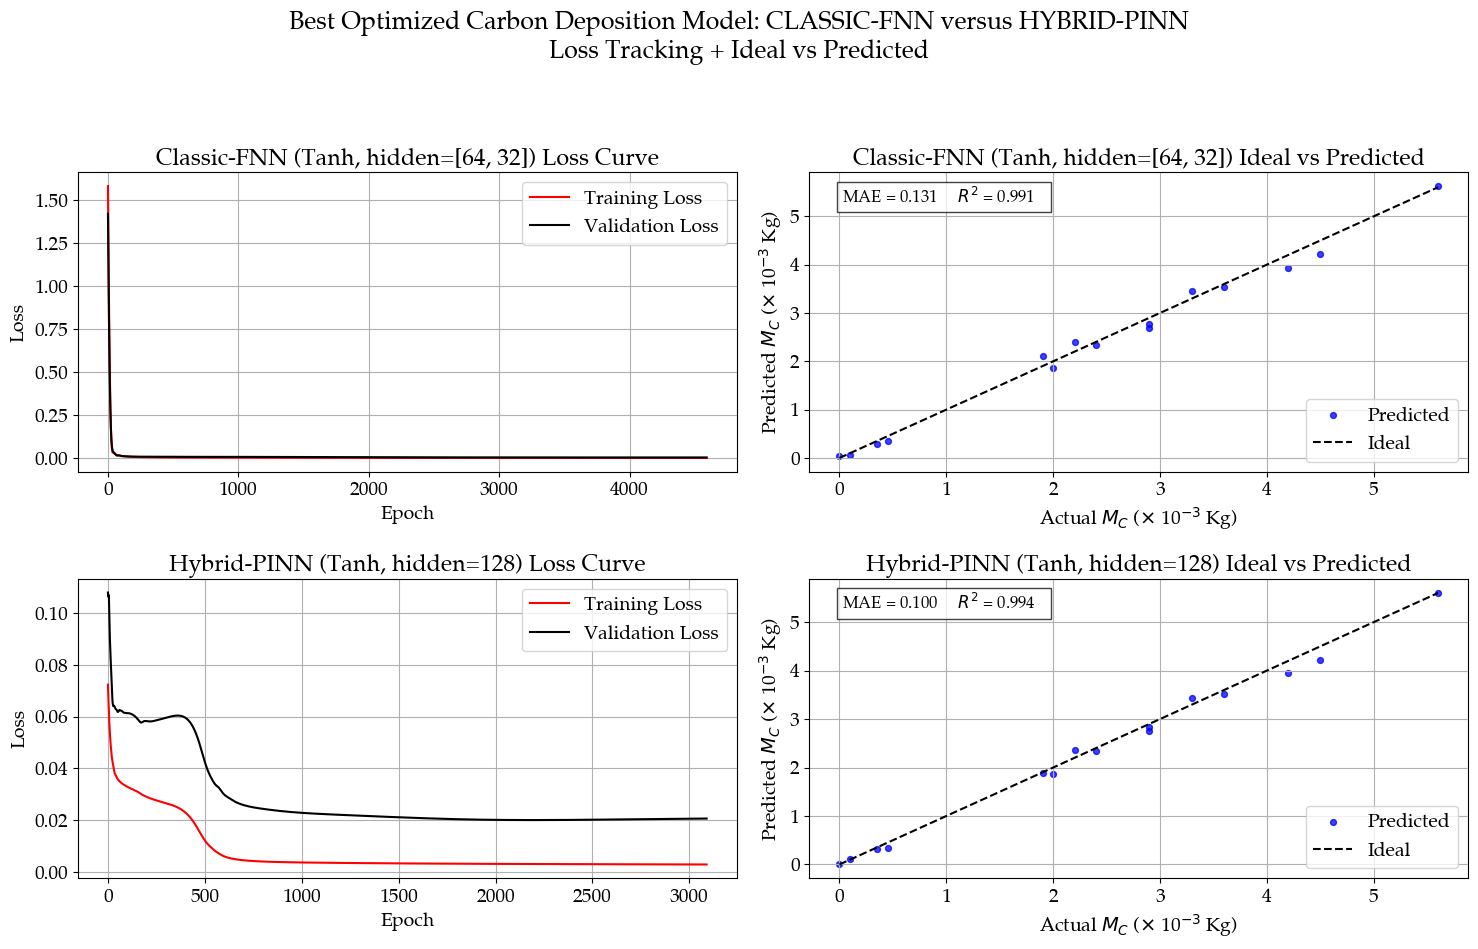

In [8]:
### GRAPHICAL PLOTS: BEST CLASSIC-FNN VERSUS BEST HYBRID-PINN ###
### Loss curves + Ideal vs Predicted Carbon Deposited Mass###

import os
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
font_path = "/content/Palatia.ttf"
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    prop = fm.FontProperties(fname=font_path)
    plt.rcParams['font.family'] = prop.get_name()
else:
    print("Palatia.ttf not found; using default matplotlib font.")

plt.rcParams['font.size'] = 14
plt.rcParams['font.weight'] = 'normal'
plt.rcParams['text.usetex'] = False

models = ["Classic-FNN", "Hybrid-PINN"]
best = {
    "Classic-FNN": FNN_BEST,
    "Hybrid-PINN": PINN_BEST
}

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
plt.subplots_adjust(wspace=0.35, hspace=0.35)

fig.suptitle(
    "Best Optimized Carbon Deposition Model: CLASSIC-FNN versus HYBRID-PINN\n"
    "Loss Tracking + Ideal vs Predicted",
    fontsize=18
)

for idx, name in enumerate(models):
    info = best[name]
    act = info["act"]
    hidden = info["hidden"]

    ## Plot 1: Train vs Validation loss ##
    ax1 = axes[idx, 0]
    tr_losses = info.get("train_losses", [])
    va_losses = info.get("val_losses", [])

    if len(tr_losses) > 0:
        ax1.plot(tr_losses, label="Training Loss",color="red")
    if len(va_losses) > 0:
        ax1.plot(va_losses, label="Validation Loss",color="black")

    ax1.set_title(f"{name} ({act}, hidden={hidden}) Loss Curve")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)

    ## Plot 2: True vs Predicted Carbon Mass Deposited ##
    ax2 = axes[idx, 1]
    y_true = info["y_true"].flatten()
    y_pred = info["y_pred"].flatten()

    ax2.scatter(y_true, y_pred, s=18, alpha=0.75, label="Predicted",color="blue")

    ## Diagonal (ideal) ##
    lo, hi = float(np.min(y_true)), float(np.max(y_true))
    ax2.plot([lo, hi], [lo, hi], linestyle="--", label="Ideal",color="black")

    ## Annotate error metrics + time ##
    ax2.text(
        0.05, 0.95,
        (f"MAE = {info['mae']:.3f}\t"
         f"$R^2$ = {info['r2']:.3f}\t"
        #  f"Train Time= {info['train_time_sec']:.1f}s \t"
        #  f"Wall Time = {info['wall_time_sec']:.1f}s"
         ),
        transform=ax2.transAxes,
        fontsize=12,
        verticalalignment="top",
        bbox=dict(facecolor="white", alpha=0.75)
    )

    ax2.set_title(f"{name} ({act}, hidden={hidden}) Ideal vs Predicted")
    ax2.set_xlabel(r"Actual $M_C$ ($\times$ 10$^{-3}$ Kg)")
    ax2.set_ylabel(r"Predicted $M_C$ ($\times$ 10$^{-3}$ Kg)")
    ax2.legend()
    ax2.grid(True)

plt.tight_layout(rect=[0, 0.03, 1, 0.94])
plt.savefig("Best_FNN_vs_Best_Hybrid_PINN_Mass.png", dpi=600)
plt.show()